# Modelling and Evaluation

---

1. Import packages
2. Load data
3. Modelling:
   * Data sampling
   * Model Training
4. Evaluation
5. Intepretation & Conclusion
---

## 1. Import packages

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
from datetime import datetime
import matplotlib.pyplot as plt

# Shows plots in jupyter notebook
%matplotlib inline

# Set plot style
sns.set(color_codes=True)

---
## 2. Load data

In [3]:
df = pd.read_csv('./data_for_predictions.csv')
df.drop(columns=["Unnamed: 0"], inplace=True)
df.head()

,id,cons_12m,cons_gas_12m,cons_last_month,forecast_cons_12m,forecast_discount_energy,forecast_meter_rent_12m,forecast_price_energy_off_peak,forecast_price_energy_peak,forecast_price_pow_off_peak,...,months_modif_prod,months_renewal,channel_MISSING,channel_ewpakwlliwisiwduibdlfmalxowmwpci,channel_foosdfpfkusacimwkcsosbicdxkicaua,channel_lmkebamcaaclubfxadlmueccxoimlema,channel_usilxuppasemubllopkaafesmlibmsdf,origin_up_kamkkxfxxuwbdslkwifmmcsiusiuosws,origin_up_ldkssxwpmemidmecebumciepifcamkci,origin_up_lxidpiddsbxsbosboudacockeimpuepw
0,24011ae4ebbe3035111d65fa7c15bc57,0.000000,4.739944,0.000000,0.000000,0.0,0.444045,0.114481,0.098142,40.606701,...,2,6,0,0,1,0,0,0,0,1
1,d29c2c54acc38ff3c0614d0a653813dd,3.668479,0.000000,0.000000,2.280920,0.0,1.237292,0.145711,0.000000,44.311378,...,76,4,1,0,0,0,0,1,0,0
2,764c75f661154dac3a6c254cd082ea7d,2.736397,0.000000,0.000000,1.689841,0.0,1.599009,0.165794,0.087899,44.311378,...,68,8,0,0,1,0,0,1,0,0
3,bba03439a292a1e166f80264c16191cb,3.200029,0.000000,0.000000,2.382089,0.0,1.318689,0.146694,0.000000,44.311378,...,69,9,0,0,0,1,0,1,0,0
4,149d57cf92fc41cf94415803a877cb4b,3.646011,0.000000,2.721811,2.650065,0.0,2.122969,0.116900,0.100015,40.606701,...,71,9,1,0,0,0,0,1,0,0


In [4]:
model_df = pd.read_csv("./data_for_predictions.csv")

# Drop artifact index columns from previous export, if any
model_df = model_df.drop(columns=["Unnamed: 0"], errors="ignore")

print("Dataset shape:", model_df.shape)
print("\nClass distribution for churn:")
print(model_df["churn"].value_counts())

print("\nColumns with missing values:")
missing = model_df.isna().sum()
print(missing[missing > 0])


Dataset shape: (14606, 63)

Class distribution for churn:
churn
0    13187
1     1419
Name: count, dtype: int64

Columns with missing values:
Series([], dtype: int64)


---

## 3. Modelling

We now have a dataset containing features that we have engineered and we are ready to start training a predictive model. Remember, we only need to focus on training a `Random Forest` classifier.

In [5]:
from sklearn import metrics
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

### Data sampling

The first thing we want to do is split our dataset into training and test samples. The reason why we do this, is so that we can simulate a real life situation by generating predictions for our test sample, without showing the predictive model these data points. This gives us the ability to see how well our model is able to generalise to new data, which is critical.

A typical % to dedicate to testing is between 20-30, for this example we will use a 75-25% split between train and test respectively.

In [6]:
# Make a copy of our data
train_df = df.copy()

# Separate target variable from independent variables
y = df['churn']
X = df.drop(columns=['id', 'churn'])
print(X.shape)
print(y.shape)

(14606, 61)
(14606,)


In [7]:
from sklearn.model_selection import train_test_split

# Separate the target from the features
y = model_df["churn"]
X = model_df.drop(columns=["id", "churn"])

# Reserve 25% of the data as the test set
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training features shape:", X_train.shape)
print("Training target shape:", y_train.shape)
print("Test features shape:", X_test.shape)
print("Test target shape:", y_test.shape)

print("\nChurn proportion in the training set:")
print(y_train.value_counts(normalize=True).round(3))

print("\nChurn proportion in the test set:")
print(y_test.value_counts(normalize=True).round(3))


Training features shape: (10954, 61)
Training target shape: (10954,)
Test features shape: (3652, 61)
Test target shape: (3652,)

Churn proportion in the training set:
churn
0    0.903
1    0.097
Name: proportion, dtype: float64

Churn proportion in the test set:
churn
0    0.903
1    0.097
Name: proportion, dtype: float64


### Model training

We trained a Random Forest classifier using the data_for_predictions.csv dataset. The data was split into training and test sets, with 75% used for training and 25% reserved for testing. We used stratified sampling so that the proportion of customers who churned stayed similar in both sets.

The dataset has more customers who did not churn than customers who did. We used class_weight="balanced" to give more weight to the less common churn class during training.

The Random Forest model uses 200 decision trees. Each tree learns patterns from the training data, and the model combines their results to make predictions. We set random_state=42 so the results can be reproduced. Random Forest can learn non-linear patterns, and the features do not need to be scaled for this model.

We also used part of the training data as validation data to compare classification thresholds. The test data was kept for the final evaluation. In the evaluation section, we compare thresholds of 0.5 and 0.2 to show the business trade-off between finding more customers at risk of churn and keeping the follow-up list manageable.

In [8]:
model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

model.fit(X_train, y_train)

print(" Random Forest has been trained. ")

 Random Forest has been trained. 


In [9]:
# Make a prediction for testing Data

y_pred = model.predict(X_test)
print("First 10 predictions:", y_pred[:10])

First 10 predictions: [0 0 0 1 0 0 0 0 0 0]


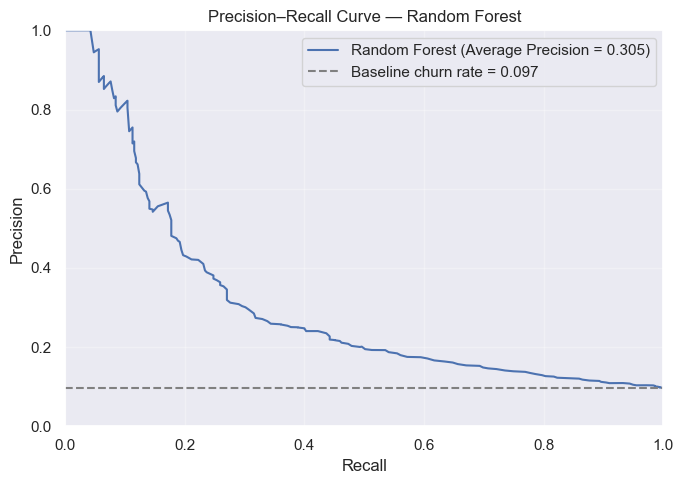

Average precision: 0.305


In [10]:

y_test_prob = model.predict_proba(X_test)[:, 1]
precision_values, recall_values, thresholds = metrics.precision_recall_curve(
    y_test,
    y_test_prob
)

average_precision = metrics.average_precision_score(y_test, y_test_prob)
churn_baseline = y_test.mean()

plt.figure(figsize=(7, 5))
plt.plot(
    recall_values,
    precision_values,
    label=f"Random Forest (Average Precision = {average_precision:.3f})"
)
plt.axhline(
    churn_baseline,
    color="gray",
    linestyle="--",
    label=f"Baseline churn rate = {churn_baseline:.3f}"
)

plt.title("Precision–Recall Curve — Random Forest")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Average precision: {average_precision:.3f}")

In [11]:
# Split validation data from the training set; the test set remains untouched
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

validation_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

validation_model.fit(X_fit, y_fit)
y_val_prob = validation_model.predict_proba(X_val)[:, 1]

# Compare thresholds and the percentage of customers flagged
for threshold in [0.5, 0.4, 0.3, 0.2]:
    y_val_pred = (y_val_prob >= threshold).astype(int)

    precision = metrics.precision_score(
        y_val, y_val_pred, zero_division=0
    )
    recall = metrics.recall_score(
        y_val, y_val_pred, zero_division=0
    )
    f1 = metrics.f1_score(
        y_val, y_val_pred, zero_division=0
    )
    flagged_rate = y_val_pred.mean()

    print(
        f"Threshold: {threshold:.1f} | "
        f"Precision: {precision:.3f} | "
        f"Recall: {recall:.3f} | "
        f"F1: {f1:.3f} | "
        f"Customers flagged: {flagged_rate:.1%}"
    )

Threshold: 0.5 | Precision: 0.525 | Recall: 0.146 | F1: 0.228 | Customers flagged: 2.7%
Threshold: 0.4 | Precision: 0.338 | Recall: 0.221 | F1: 0.267 | Customers flagged: 6.3%
Threshold: 0.3 | Precision: 0.214 | Recall: 0.362 | F1: 0.269 | Customers flagged: 16.4%
Threshold: 0.2 | Precision: 0.150 | Recall: 0.554 | F1: 0.236 | Customers flagged: 36.0%


In [12]:
selected_threshold = 0.2

# Generate final predictions on the test set using the tuned threshold
y_test_prob = model.predict_proba(X_test)[:, 1]
y_test_pred_final = (y_test_prob >= selected_threshold).astype(int)

final_conf_matrix = metrics.confusion_matrix(
    y_test,
    y_test_pred_final
)

print("Threshold:", selected_threshold)
print("Confusion matrix:\n", final_conf_matrix)
print(f"\nAccuracy : {metrics.accuracy_score(y_test, y_test_pred_final):.3f}")
print(f"Precision: {metrics.precision_score(y_test, y_test_pred_final, zero_division=0):.3f}")
print(f"Recall   : {metrics.recall_score(y_test, y_test_pred_final, zero_division=0):.3f}")
print(f"F1-score : {metrics.f1_score(y_test, y_test_pred_final, zero_division=0):.3f}")
print(f"ROC-AUC  : {metrics.roc_auc_score(y_test, y_test_prob):.3f}")


Threshold: 0.2
Confusion matrix:
 [[2147 1150]
 [ 130  225]]

Accuracy : 0.650
Precision: 0.164
Recall   : 0.634
F1-score : 0.260
ROC-AUC  : 0.698


In [13]:
print("Total churn across the entire dataset:")
print(y.value_counts().sort_index())

print("\nChurn proportion across the entire dataset:")
print(y.value_counts(normalize=True).sort_index())

print("\nChurn proportion in the training set:")
print(y_train.value_counts(normalize=True).sort_index())

print("\nChurn proportion in the test set:")
print(y_test.value_counts(normalize=True).sort_index())


Total churn across the entire dataset:
churn
0    13187
1     1419
Name: count, dtype: int64

Churn proportion across the entire dataset:
churn
0    0.902848
1    0.097152
Name: proportion, dtype: float64

Churn proportion in the training set:
churn
0    0.902867
1    0.097133
Name: proportion, dtype: float64

Churn proportion in the test set:
churn
0    0.902793
1    0.097207
Name: proportion, dtype: float64


In [14]:
y_test_prob = model.predict_proba(X_test)[:, 1]

print("Actual class distribution in the test set:")
print(y_test.value_counts().sort_index())
print(f"\nROC-AUC: {metrics.roc_auc_score(y_test, y_test_prob):.3f}")

# Compare performance between the standard and the tuned threshold
for threshold in [0.5, 0.2]:
    y_test_pred_check = (y_test_prob >= threshold).astype(int)

    print(f"\nThreshold: {threshold}")
    print("Confusion matrix:")
    print(metrics.confusion_matrix(y_test, y_test_pred_check))
    print(f"Precision: {metrics.precision_score(y_test, y_test_pred_check, zero_division=0):.3f}")
    print(f"Recall:    {metrics.recall_score(y_test, y_test_pred_check, zero_division=0):.3f}")
    print(f"F1-score:  {metrics.f1_score(y_test, y_test_pred_check, zero_division=0):.3f}")


Actual class distribution in the test set:
churn
0    3297
1     355
Name: count, dtype: int64

ROC-AUC: 0.698

Threshold: 0.5
Confusion matrix:
[[3239   58]
 [ 292   63]]
Precision: 0.521
Recall:    0.177
F1-score:  0.265

Threshold: 0.2
Confusion matrix:
[[2147 1150]
 [ 130  225]]
Precision: 0.164
Recall:    0.634
F1-score:  0.260


### Evaluation

Now let's evaluate how well this trained model is able to predict the values of the test dataset.

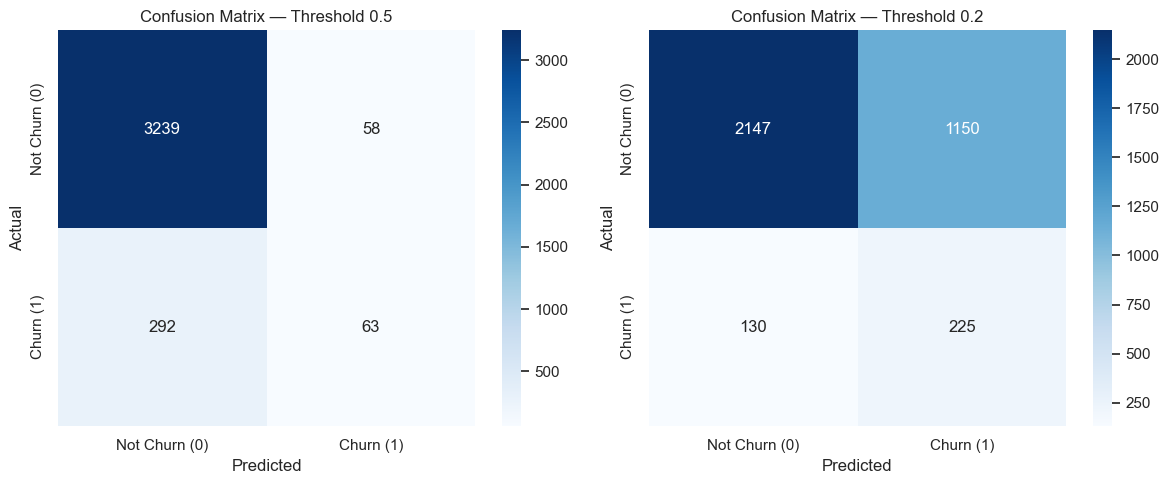

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

thresholds = [0.5, 0.2]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, threshold in zip(axes, thresholds):
    # Predict churn based on the current threshold
    y_test_pred = (y_test_prob >= threshold).astype(int)

    # Calculate confusion matrix
    cm = confusion_matrix(y_test, y_test_pred)

    # Display as a heatmap
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Not Churn (0)", "Churn (1)"],
        yticklabels=["Not Churn (0)", "Churn (1)"],
        ax=ax
    )

    ax.set_title(f"Confusion Matrix — Threshold {threshold}")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()


<function matplotlib.pyplot.show(close=None, block=None)>

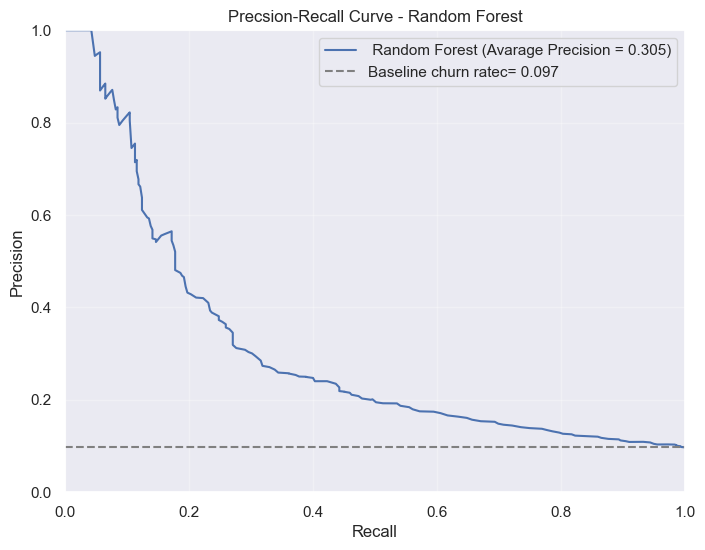

In [16]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, average_precision_score

# Calculate precision and recall on each variant Threshold
precision_values, recall_values, thresholds_pr = precision_recall_curve(
    y_test,
    y_test_prob
)

# Average Precision summarizes the curve performance
avarage_precision = average_precision_score(y_test, y_test_prob)

# The churn proportion serves as the baseline for precision
baseline = y_test.mean()

plt.figure(figsize=(8, 6))
plt.plot(
    recall_values,
    precision_values,
    label=f" Random Forest (Avarage Precision = {avarage_precision:.3f})"
)

plt.axhline(
    y=baseline,
    color="gray",
    linestyle="--",
    label=f"Baseline churn ratec= {baseline:.3f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precsion-Recall Curve - Random Forest")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)
plt.show

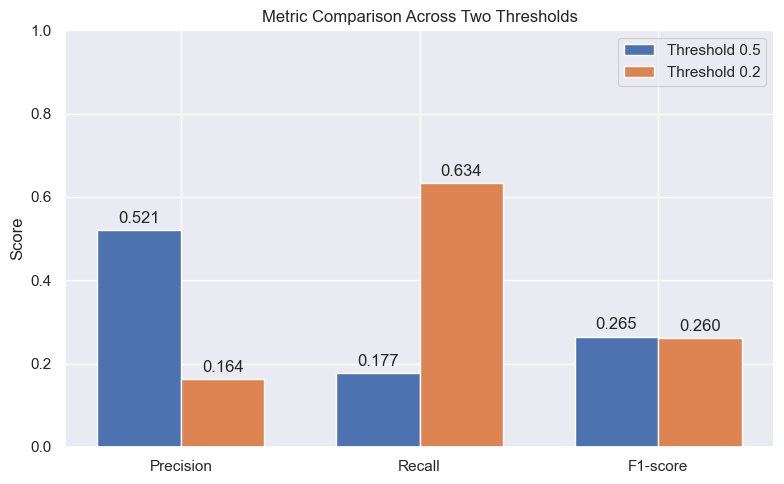

In [17]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.5, 0.2]
metric_names = ["Precision", "Recall", "F1-score"]

scores = {
    "0.5": [],
    "0.2": []
}

for threshold in thresholds:
    # Predict based on the current threshold
    y_test_pred = (y_test_prob >= threshold).astype(int)

    scores[str(threshold)] = [
        precision_score(y_test, y_test_pred, zero_division=0),
        recall_score(y_test, y_test_pred, zero_division=0),
        f1_score(y_test, y_test_pred, zero_division=0)
    ]

x = range(len(metric_names))
bar_width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))

bars_05 = ax.bar(
    [i - bar_width / 2 for i in x],
    scores["0.5"],
    width=bar_width,
    label="Threshold 0.5"
)

bars_02 = ax.bar(
    [i + bar_width / 2 for i in x],
    scores["0.2"],
    width=bar_width,
    label="Threshold 0.2"
)

ax.set_xticks(list(x))
ax.set_xticklabels(metric_names)
ax.set_ylim(0, 1)
ax.set_ylabel("Score")
ax.set_title("Metric Comparison Across Two Thresholds")
ax.legend()

ax.bar_label(bars_05, fmt="%.3f", padding=3)
ax.bar_label(bars_02, fmt="%.3f", padding=3)

plt.tight_layout()
plt.show()


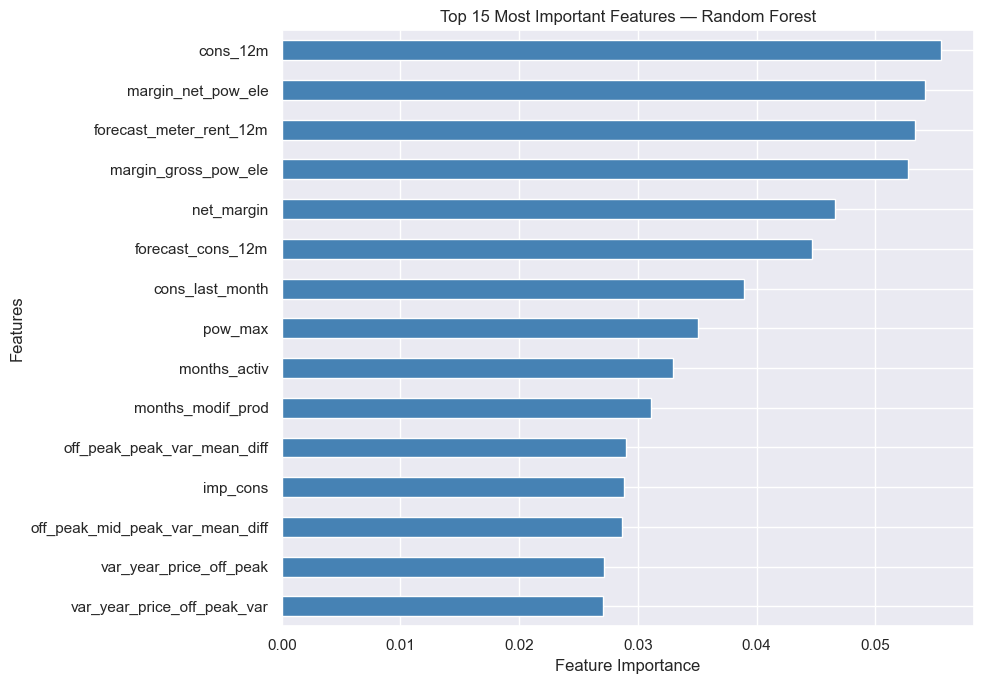

In [18]:
import pandas as pd
import matplotlib.pyplot as plt

# Get feature importance values from the model
feature_importance = pd.Series(
    model.feature_importances_,
    index=X_train.columns
)

# Select the top 15 most important features
top_features = feature_importance.nlargest(15).sort_values()

# Create a horizontal bar chart
plt.figure(figsize=(10, 7))
top_features.plot(kind="barh", color="steelblue")

plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Top 15 Most Important Features — Random Forest")
plt.tight_layout()
plt.show()


### Interpretation and conclusion

The Random Forest model was evaluated on a test set of 3,652 customers, including 355 customers who actually churned. The model achieved a ROC-AUC of 0.698 and an Average Precision of 0.305, compared with a churn baseline of 0.097. This shows that the model ranks customers by churn risk better than random guessing, although its predictive ability is still limited.

The classification threshold changes how the model turns churn probabilities into churn predictions. At a threshold of 0.5, the model identified 63 of the 355 customers who churned. Its precision was 0.521 and its recall was 0.177. The model flagged fewer customers, and about half of those flagged actually churned. This option may suit a business with limited retention team capacity or costly retention actions. The downside is that the model missed most customers who later churned.

At a threshold of 0.2, the model identified 225 of the 355 customers who churned. Recall increased to 0.634, while precision fell to 0.164. The model flagged more customers, including 1,150 who did not churn. This option may suit a business that wants to reach more at-risk customers and can follow up at low cost. The downside is that the retention team must handle a much larger customer list.

On the validation data, a threshold of 0.3 achieved the highest F1-score, at 0.269, compared with 0.5 (0.228) and 0.2 (0.236). Therefore, the test results at threshold 0.2 should be described as an option for identifying more customers who may churn, not as the threshold with the highest validation F1-score. The test F1-scores at thresholds 0.5 and 0.2 were very similar: 0.265 and 0.260, respectively.

Precision, recall, and F1-score are used because churn is the less common class, so accuracy alone may give an incomplete view of model performance. Recall shows how many customers who churned were identified. Precision shows how many flagged customers actually churned. F1-score summarizes the balance between precision and recall. ROC-AUC and the Precision–Recall curve help assess model performance across different thresholds.

Overall, this model can help the business prioritize customers, but its results are not strong enough to be the only basis for decisions. The threshold should be chosen based on the retention team’s capacity, the cost of follow-up, and the business loss from customers who churn without being retained.